In [14]:
import os
import pandas
import numpy
import seaborn as sn 
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image

print("GPU Available:", torch.cuda.is_available())

GPU Available: True


In [15]:
path = "/kaggle/input/datasets/apollo2506/eurosat-dataset"

for folder in os.listdir(path):
    print(folder)

    subpath = os.path.join(path, folder)

    if os.path.isdir(subpath):
        print(os.listdir(subpath))

EuroSAT
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake', 'label_map.json', 'test.csv', 'train.csv', 'validation.csv']
EuroSATallBands
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake', 'label_map.json', 'test.csv', 'train.csv', 'validation.csv']


In [16]:
# Count images in each class

dataset_path = "/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT"

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        images = os.listdir(class_path)

        print(class_name, ":", len(images))

AnnualCrop : 3000
Forest : 3000
HerbaceousVegetation : 3000
Highway : 2500
Industrial : 2500
Pasture : 2000
PermanentCrop : 2500
Residential : 3000
River : 2500
SeaLake : 3000


In [17]:
classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

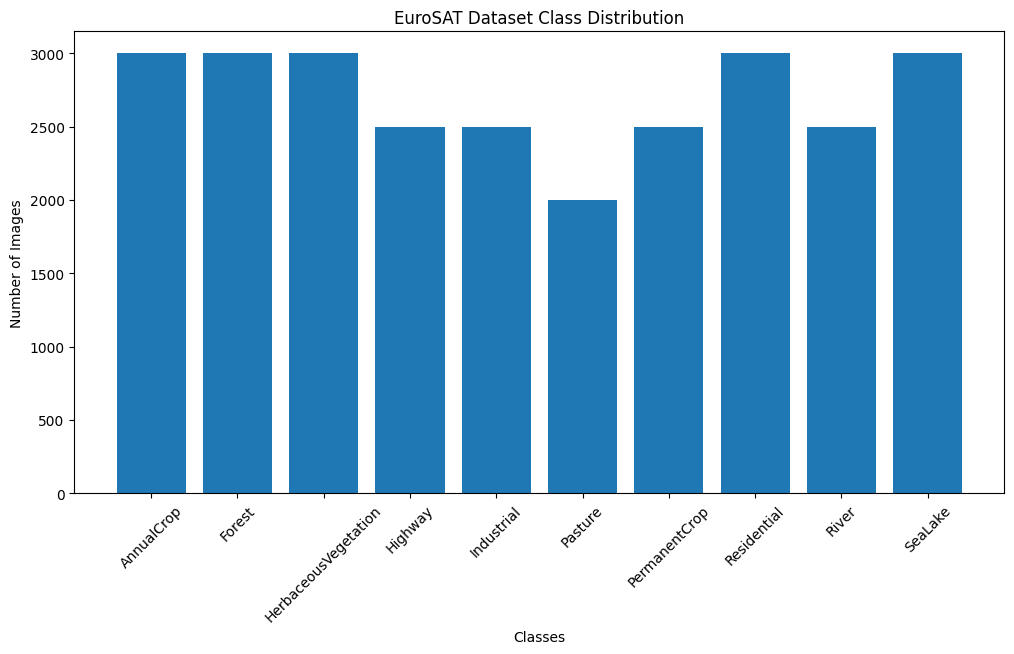

In [18]:
# Visualize Class Distribution

class_counts = {}

for class_name in sorted(classes):

    class_path = os.path.join(dataset_path, class_name)

    class_counts[class_name] = len(os.listdir(class_path))


plt.figure(figsize=(12, 6))

plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.title("EuroSAT Dataset Class Distribution")

plt.xticks(rotation=45)

plt.show()

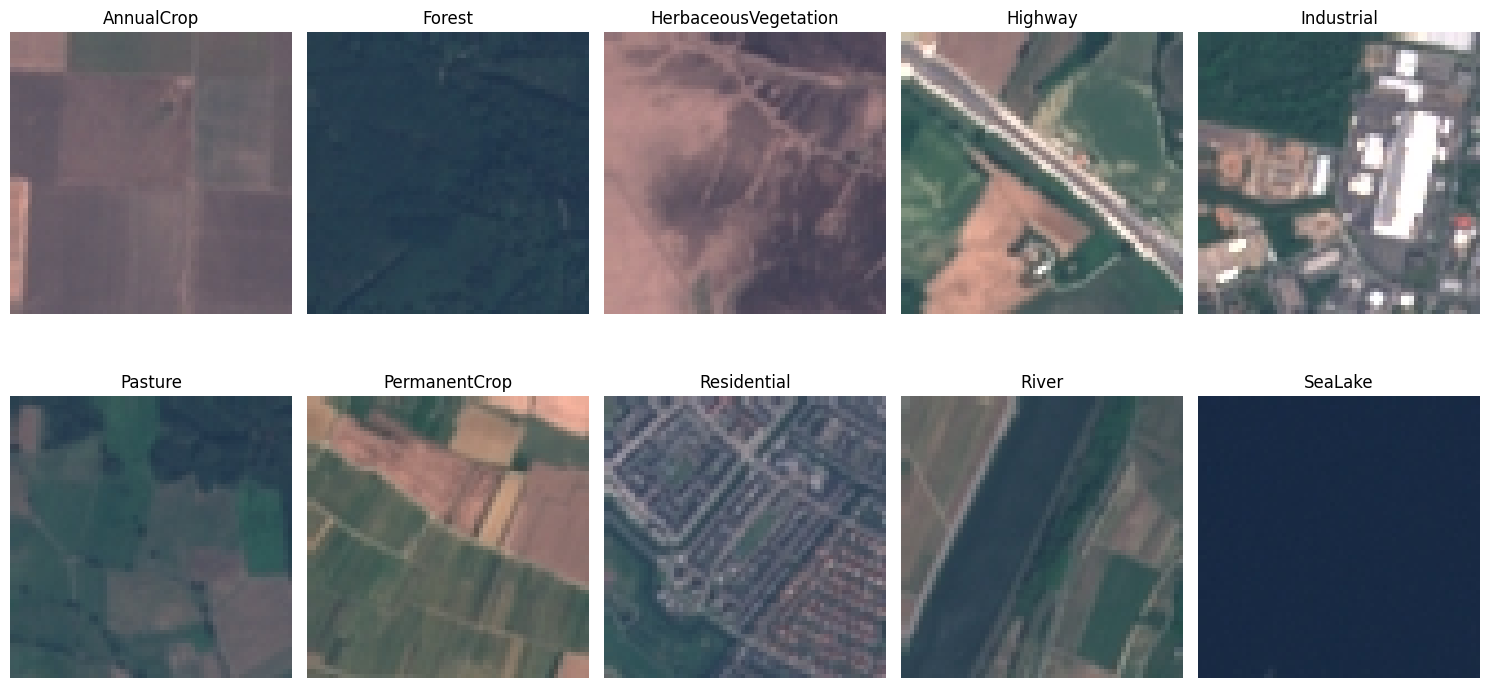

In [19]:
# Display Sample Images

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(sorted(classes)):

    class_path = os.path.join(dataset_path, class_name)

    images = os.listdir(class_path)

    image_path = os.path.join(class_path, images[0])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, i + 1)

    plt.imshow(img)

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
#  Check Image Dimensions

image_sizes = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    image_name = os.listdir(class_path)[0]

    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    image_sizes.append(img.size)

print("Image Dimensions:", set(image_sizes))

Image Dimensions: {(64, 64)}


In [21]:

# Check Image Mode

img = Image.open(image_path)

print("Image Mode:", img.mode)

Image Mode: RGB


In [22]:
#  Check Corrupted Images

corrupted_images = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        try:
            img = Image.open(image_path)
            img.verify()

        except:
            corrupted_images.append(image_path)

print("Total Corrupted Images:", len(corrupted_images))

Total Corrupted Images: 0


In [23]:
# Check Duplicate Images

import hashlib

image_hashes = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        with open(image_path, "rb") as f:
            image_hash = hashlib.md5(f.read()).hexdigest()

        image_hashes.append(image_hash)

print("Total Images:", len(image_hashes))
print("Unique Images:", len(set(image_hashes)))
print("Duplicate Images:", len(image_hashes) - len(set(image_hashes)))

Total Images: 27000
Unique Images: 27000
Duplicate Images: 0


In [24]:
#  Read CSV Files
import pandas as pd

train_df = pd.read_csv(os.path.join(dataset_path, "train.csv"))
test_df = pd.read_csv(os.path.join(dataset_path, "test.csv"))
val_df = pd.read_csv(os.path.join(dataset_path, "validation.csv"))

print("Training Dataset:")
print(train_df.head())

print("\nTesting Dataset:")
print(test_df.head())

print("\nValidation Dataset:")
print(val_df.head())

Training Dataset:
   Unnamed: 0                                           Filename  Label  \
0       16257                      AnnualCrop/AnnualCrop_142.jpg      0   
1        3297  HerbaceousVegetation/HerbaceousVegetation_2835...      2   
2       17881               PermanentCrop/PermanentCrop_1073.jpg      6   
3        2223                      Industrial/Industrial_453.jpg      4   
4        4887  HerbaceousVegetation/HerbaceousVegetation_1810...      2   

              ClassName  
0            AnnualCrop  
1  HerbaceousVegetation  
2         PermanentCrop  
3            Industrial  
4  HerbaceousVegetation  

Testing Dataset:
   Unnamed: 0                          Filename  Label    ClassName
0        2438    AnnualCrop/AnnualCrop_1275.jpg      0   AnnualCrop
1        1018   Residential/Residential_504.jpg      7  Residential
2           3           Pasture/Pasture_787.jpg      5      Pasture
3        1011  Residential/Residential_1575.jpg      7  Residential
4          47    

In [25]:
# Check Dataset Split Sizes

print("Training Images:", len(train_df))

print("Testing Images:", len(test_df))

print("Validation Images:", len(val_df))

print("Total Images:", len(train_df) + len(test_df) + len(val_df))

Training Images: 18900
Testing Images: 2700
Validation Images: 5400
Total Images: 27000


In [26]:
# Class Distribution in Each Dataset

print("Training Class Distribution:")
print(train_df["ClassName"].value_counts().sort_index())

print("\nValidation Class Distribution:")
print(val_df["ClassName"].value_counts().sort_index())

print("\nTesting Class Distribution:")
print(test_df["ClassName"].value_counts().sort_index())

Training Class Distribution:
ClassName
AnnualCrop              2100
Forest                  2100
HerbaceousVegetation    2100
Highway                 1750
Industrial              1750
Pasture                 1400
PermanentCrop           1750
Residential             2100
River                   1750
SeaLake                 2100
Name: count, dtype: int64

Validation Class Distribution:
ClassName
AnnualCrop              600
Forest                  600
HerbaceousVegetation    600
Highway                 500
Industrial              500
Pasture                 400
PermanentCrop           500
Residential             600
River                   500
SeaLake                 600
Name: count, dtype: int64

Testing Class Distribution:
ClassName
AnnualCrop              300
Forest                  300
HerbaceousVegetation    300
Highway                 250
Industrial              250
Pasture                 200
PermanentCrop           250
Residential             300
River                   250
SeaLak

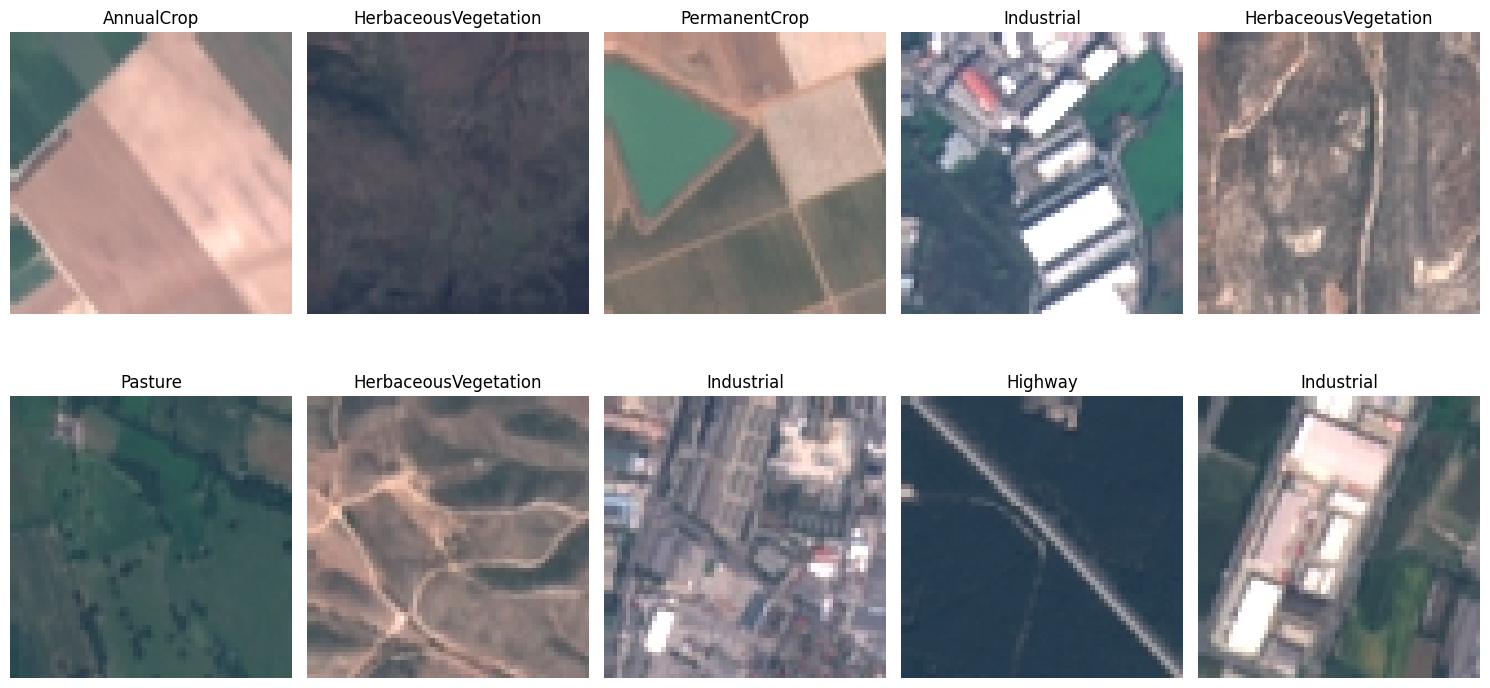

In [27]:
# Display Images Using Training CSV

plt.figure(figsize=(15, 8))

for i in range(10):

    image_name = train_df.iloc[i]["Filename"]

    image_path = os.path.join(dataset_path, image_name)

    img = Image.open(image_path).convert("RGB")

    class_name = train_df.iloc[i]["ClassName"]

    plt.subplot(2, 5, i + 1)

    plt.imshow(img)

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
# Check Pixel Values
import numpy as np

img = Image.open(image_path).convert("RGB")

img_array = np.array(img)

print("Minimum Pixel Value:", img_array.min())

print("Maximum Pixel Value:", img_array.max())

print("Image Shape:", img_array.shape)

Minimum Pixel Value: 41
Maximum Pixel Value: 255
Image Shape: (64, 64, 3)


In [29]:
# Calculate RGB Mean

channel_sum = np.zeros(3)
total_pixels = 0

for filename in train_df["Filename"]:

    image_path = os.path.join(dataset_path, filename)

    img = Image.open(image_path).convert("RGB")

    img_array = np.array(img) / 255.0

    channel_sum += img_array.sum(axis=(0, 1))

    total_pixels += img_array.shape[0] * img_array.shape[1]

mean = channel_sum / total_pixels

print("RGB Mean:", mean)

RGB Mean: [0.3444954  0.38034746 0.40780443]


In [30]:
# Calculate RGB Standard Deviation

channel_squared_sum = np.zeros(3)
total_pixels = 0

for filename in train_df["Filename"]:

    image_path = os.path.join(dataset_path, filename)

    img = Image.open(image_path).convert("RGB")

    img_array = np.array(img) / 255.0

    channel_squared_sum += (img_array ** 2).sum(axis=(0, 1))

    total_pixels += img_array.shape[0] * img_array.shape[1]

std = np.sqrt((channel_squared_sum / total_pixels) - (mean ** 2))

print("RGB Standard Deviation:", std)

RGB Standard Deviation: [0.20310571 0.13712056 0.11566022]


In [31]:
#  Define Normalization Values

mean = [0.3444954, 0.38034746, 0.40780443]

std = [0.20310571, 0.13712056, 0.11566022]

print("Mean:", mean)
print("Standard Deviation:", std)

Mean: [0.3444954, 0.38034746, 0.40780443]
Standard Deviation: [0.20310571, 0.13712056, 0.11566022]


In [32]:
# Define Image Transformations
from torchvision import transforms

transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(mean=mean, std=std)

])

print("Image transformations defined successfully!")

Image transformations defined successfully!


In [33]:
class EuroSAT_CNN(nn.Module):

    def __init__(self, num_classes=10):
        super(EuroSAT_CNN, self).__init__()

        self.feature = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(

            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.feature(x)
        x = self.avgpool(x)
        x = self.classifier(x)

        return x

In [34]:
from PIL import Image
import os
import torch
from torch.utils.data import Dataset

class EuroSATDataset(Dataset):

    def __init__(self, df, root_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = os.path.join(
            self.root_dir,
            self.df.iloc[idx]['Filename']
        )

        image = Image.open(img_path).convert('RGB')
        label = int(self.df.iloc[idx]['Label'])

        if self.transform:
            image = self.transform(image)

        return image, label

In [35]:
image_dir = "/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT"

train_data = EuroSATDataset(train_df, image_dir, transform)
val_data = EuroSATDataset(val_df, image_dir, transform)
test_data = EuroSATDataset(test_df, image_dir, transform)

In [36]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)



In [37]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 64, 64])
torch.Size([32])


In [38]:
model = EuroSAT_CNN(num_classes=10)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Model initialized successfully!")
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Model initialized successfully!
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [39]:
num_epochs = 25

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}, "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/25], Loss: 1.0091, Accuracy: 65.06%
Epoch [2/25], Loss: 0.7386, Accuracy: 74.50%
Epoch [3/25], Loss: 0.6242, Accuracy: 78.40%
Epoch [4/25], Loss: 0.5876, Accuracy: 79.75%
Epoch [5/25], Loss: 0.5384, Accuracy: 81.67%
Epoch [6/25], Loss: 0.4959, Accuracy: 83.17%
Epoch [7/25], Loss: 0.4492, Accuracy: 84.75%
Epoch [8/25], Loss: 0.4105, Accuracy: 86.35%
Epoch [9/25], Loss: 0.3960, Accuracy: 86.83%
Epoch [10/25], Loss: 0.3604, Accuracy: 87.65%
Epoch [11/25], Loss: 0.3556, Accuracy: 87.93%
Epoch [12/25], Loss: 0.3158, Accuracy: 89.46%
Epoch [13/25], Loss: 0.3052, Accuracy: 89.54%
Epoch [14/25], Loss: 0.2935, Accuracy: 89.92%
Epoch [15/25], Loss: 0.2828, Accuracy: 90.29%
Epoch [16/25], Loss: 0.2737, Accuracy: 90.74%
Epoch [17/25], Loss: 0.2651, Accuracy: 91.01%
Epoch [18/25], Loss: 0.2455, Accuracy: 91.82%
Epoch [19/25], Loss: 0.2407, Accuracy: 92.09%
Epoch [20/25], Loss: 0.2429, Accuracy: 91.86%
Epoch [21/25], Loss: 0.2225, Accuracy: 92.42%
Epoch [22/25], Loss: 0.2237, Accuracy: 92.5

In [40]:
# Set model to evaluation mode
model.eval()

val_loss = 0.0
val_correct = 0
val_total = 0

# Disable gradient calculation
with torch.no_grad():

    for images, labels in val_loader:

        # Make predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        val_loss += loss.item()

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        val_total += labels.size(0)
        val_correct += (predicted == labels).sum().item()


# Calculate validation loss and accuracy
val_loss = val_loss / len(val_loader)

val_accuracy = 100 * val_correct / val_total

# Display results
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 2), "%")

Validation Loss: 0.2994
Validation Accuracy: 91.22 %


In [41]:
model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)

        test_correct += (predicted == labels).sum().item()


test_accuracy = 100 * test_correct / test_total

print("Test Accuracy:", round(test_accuracy, 2), "%")

Test Accuracy: 92.19 %


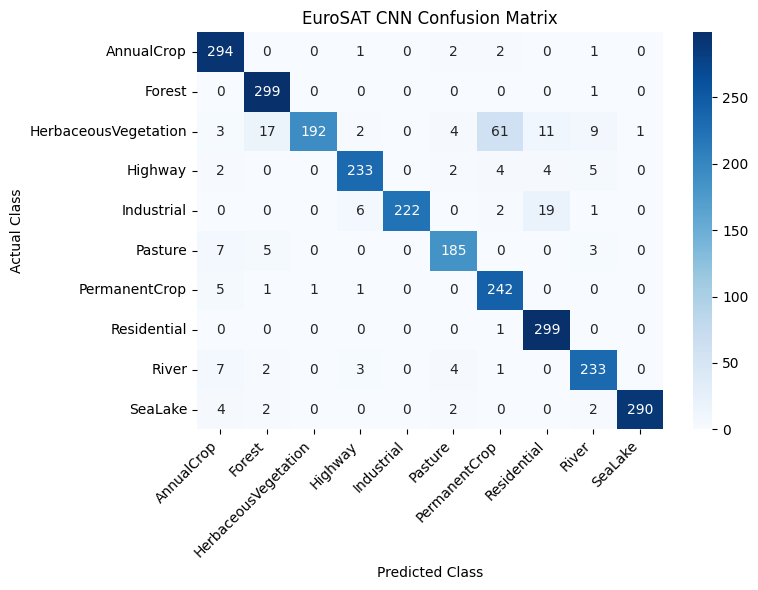

In [42]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())


# Create confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

# Get class names
class_names = [
    'AnnualCrop',
    'Forest',
    'HerbaceousVegetation',
    'Highway',
    'Industrial',
    'Pasture',
    'PermanentCrop',
    'Residential',
    'River',
    'SeaLake'
]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EuroSAT CNN Confusion Matrix")

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [43]:

import torch

# Save model weights
torch.save(model.state_dict(), "EuroSAT_CNN_Model.pth")

print("EuroSAT CNN model saved successfully!")


EuroSAT CNN model saved successfully!


In [44]:

checkpoint = {
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'epoch': epoch,
    'class_names': class_names
}

torch.save(checkpoint, "EuroSAT_CNN_Checkpoint.pth")

print("Complete checkpoint saved successfully!")


Complete checkpoint saved successfully!
